# Text Extraction on Plate Number (Version 2)
Reads every plate image found in the `Images` folder, so it works with any number of photos (the original activity used 5 plate types).

In [15]:
import glob
import os

import cv2
import pytesseract
from matplotlib import pyplot as plt

# --- Settings -------------------------------------------------------------
pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

IMAGE_FOLDER = "Images"      # folder that holds the plate pictures
NAME_PREFIX = "plate"        # picks up platenum.png, platenumber.png, ...

# What do your photos contain?
#   "plate_number_only" -> the picture is just the plate number (no border, no bottom text)
#   "full_plate"        -> the whole plate; crop to the number line first
PHOTO_TYPE = "plate_number_only"

# Only used when PHOTO_TYPE = "full_plate" (fractions of height / width).
CROP_TOP, CROP_BOTTOM = 0.15, 0.68
CROP_LEFT, CROP_RIGHT = 0.05, 0.95

In [16]:
def preprocess_plate(img):
    """Crop to the plate number line, binarize (Otsu), force black-on-white, pad."""
    h, w = img.shape[:2]
    if PHOTO_TYPE == "full_plate":
        crop = img[int(h * CROP_TOP):int(h * CROP_BOTTOM), int(w * CROP_LEFT):int(w * CROP_RIGHT)]
    else:
        crop = img   # the photo is already just the plate number

    # Small images read poorly: enlarge so the text is at least ~100 px tall
    if crop.shape[0] < 100:
        f = 100 / crop.shape[0]
        crop = cv2.resize(crop, None, fx=f, fy=f, interpolation=cv2.INTER_CUBIC)

    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Make sure it's black text on a white background
    if cv2.countNonZero(thresh) < thresh.size / 2:
        thresh = cv2.bitwise_not(thresh)

    # White padding around the text
    return cv2.copyMakeBorder(thresh, 20, 20, 20, 20, cv2.BORDER_CONSTANT, value=255)


def ocr_image(image_path):
    """Read one plate image: show original + processed, return the extracted text."""
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Could not open image: {os.path.abspath(image_path)}")

    processed = preprocess_plate(img)
    text = pytesseract.image_to_string(processed, config="--psm 7").strip()   # one line of text

    fig, axs = plt.subplots(1, 2, figsize=(12, 6))
    axs[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axs[0].set_title(os.path.basename(image_path))
    axs[1].imshow(processed, cmap="gray")
    axs[1].set_title("Processed for OCR")
    for ax in axs:
        ax.axis("off")
    plt.show()

    return text

Working folder: c:\Users\man\Documents\DSP
Found 2 plate image(s): ['platenum.png', 'platenumber.png']


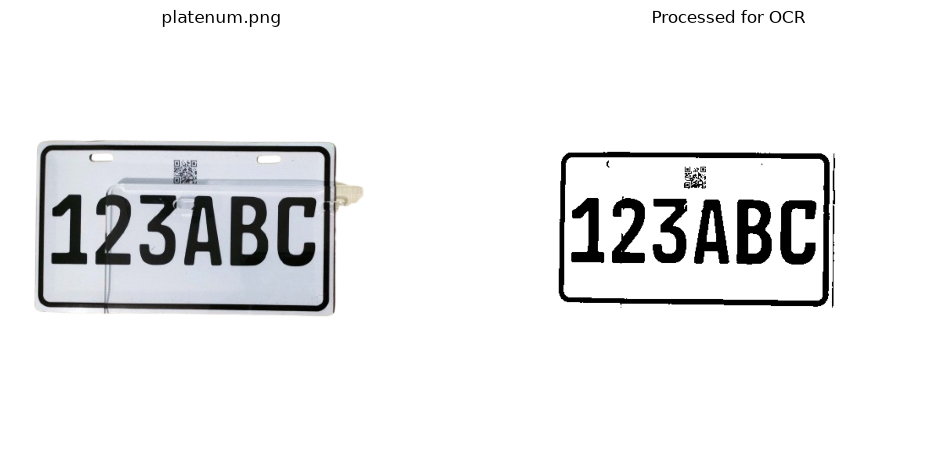

platenum.png -> Extracted Text: 123ABC,


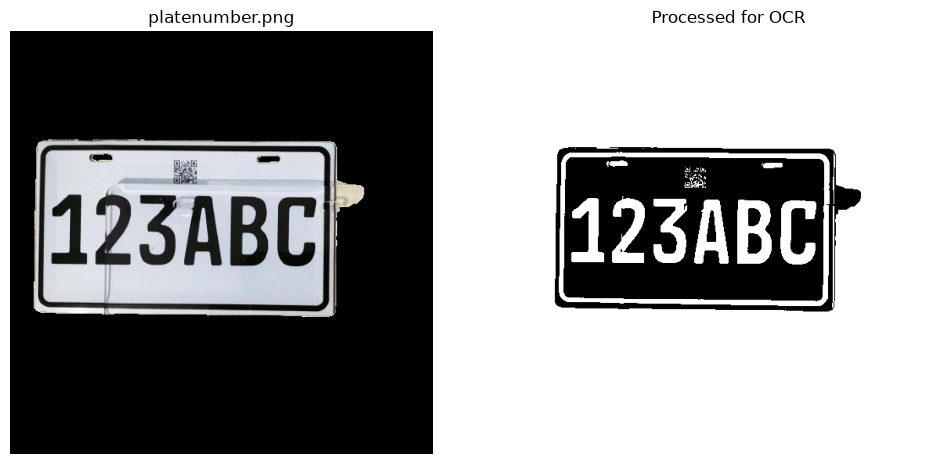

platenumber.png -> Extracted Text: 

--- Summary ---
platenum.png                        123ABC,
platenumber.png                     


In [18]:
# Find every plate image in the folder (png / jpg / jpeg)
print("Working folder:", os.getcwd())
paths = sorted(
    p for ext in ("png", "jpg", "jpeg")
    for p in glob.glob(os.path.join(IMAGE_FOLDER, f"{NAME_PREFIX}*.{ext}"))
)
if not paths:
    raise FileNotFoundError(
        f"No images starting with '{NAME_PREFIX}' found in '{os.path.abspath(IMAGE_FOLDER)}'.")
print(f"Found {len(paths)} plate image(s):", [os.path.basename(p) for p in paths])

# Run OCR on each one
results = {}
for path in paths:
    results[os.path.basename(path)] = ocr_image(path)
    print(f"{os.path.basename(path)} -> Extracted Text: {results[os.path.basename(path)]}")

# Summary
print("\n--- Summary ---")
for name, text in results.items():
    print(f"{name:35s} {text}")